In [29]:
import pandas as pd
import matplotlib.pyplot as plt

In [30]:
df = pd.read_csv("../Data/a60ff60d-d00f-4f89-9d8a-dbf275e8c35b.csv")

In [31]:
df.head()

,_id,Fecha,Hora,Noroeste ozono,Noroeste dioxido de azufre,Noroeste dioxido de nitrogeno,Noroeste monoxido de carbono,Noroeste PM10,Noroeste PM25,Noreste ozono,...,Suroeste dioxido de nitrogeno,Suroeste monoxido de carbono,Suroeste PM10,Suroeste PM25,Sureste ozono,Sureste dioxido de azufre,Sureste dioxido de nitrogeno,Sureste monoxido de carbono,Sureste PM10,Sureste PM25
0,1,2022-01-01T00:00:00,1,4.0,8,24.0,15.0,114,82.0,15.0,...,26.0,7.0,58,72.0,18.0,4,19.0,10.0,102,95
1,2,2022-01-01T00:00:00,2,4.0,8,23.0,16.0,115,83.0,16.0,...,16.0,7.0,60,75.0,15.0,4,18.0,11.0,103,99
2,3,2022-01-01T00:00:00,3,3.0,8,22.0,18.0,118,85.0,7.0,...,21.0,8.0,67,79.0,14.0,4,20.0,13.0,103,99
3,4,2022-01-01T00:00:00,4,3.0,8,21.0,21.0,122,87.0,4.0,...,20.0,8.0,73,85.0,10.0,4,20.0,13.0,103,106
4,5,2022-01-01T00:00:00,5,7.0,8,20.0,22.0,127,91.0,4.0,...,17.0,9.0,77,90.0,9.0,4,20.0,13.0,104,111


In [32]:
# df["Fecha"] = pd.to_datetime(df["Fecha"], format="%Y-%m-%dT%H:%M:%S")

df["PM10 Promedio"] = (df["Noroeste PM10"] + df["Noreste PM10"] + df["Sureste PM10"] + df["Suroeste PM10"] + df["Centro PM10"]) / 5
df["PM25 Promedio"] = (df["Noroeste PM25"] + df["Noreste PM25"] + df["Sureste PM25"] + df["Suroeste PM25"] + df["Centro PM25"])

df["PM10 Rolling"] = df.rolling(window=3, on="Fecha")["PM10 Promedio"].mean()
df["PM25 Rolling"] = df.rolling(window=3, on="Fecha")["PM25 Promedio"].mean()

df.head()

,_id,Fecha,Hora,Noroeste ozono,Noroeste dioxido de azufre,Noroeste dioxido de nitrogeno,Noroeste monoxido de carbono,Noroeste PM10,Noroeste PM25,Noreste ozono,...,Sureste ozono,Sureste dioxido de azufre,Sureste dioxido de nitrogeno,Sureste monoxido de carbono,Sureste PM10,Sureste PM25,PM10 Promedio,PM25 Promedio,PM10 Rolling,PM25 Rolling
0,1,2022-01-01T00:00:00,1,4.0,8,24.0,15.0,114,82.0,15.0,...,18.0,4,19.0,10.0,102,95,94.4,430.0,NaN,NaN
1,2,2022-01-01T00:00:00,2,4.0,8,23.0,16.0,115,83.0,16.0,...,15.0,4,18.0,11.0,103,99,95.4,442.0,NaN,NaN
2,3,2022-01-01T00:00:00,3,3.0,8,22.0,18.0,118,85.0,7.0,...,14.0,4,20.0,13.0,103,99,98.6,451.0,96.133333,441.000000
3,4,2022-01-01T00:00:00,4,3.0,8,21.0,21.0,122,87.0,4.0,...,10.0,4,20.0,13.0,103,106,102.2,474.0,98.733333,455.666667
4,5,2022-01-01T00:00:00,5,7.0,8,20.0,22.0,127,91.0,4.0,...,9.0,4,20.0,13.0,104,111,106.0,495.0,102.266667,473.333333


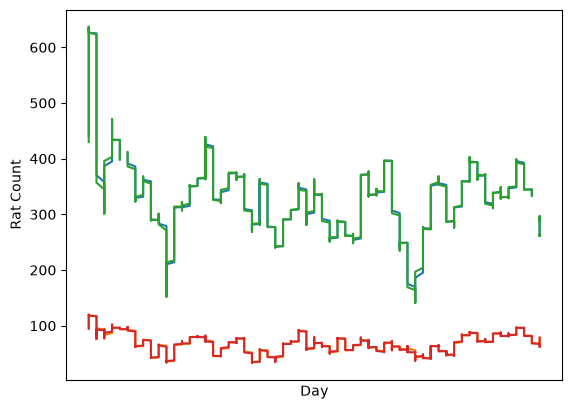

In [33]:
# Graficado de datos
plt.plot(df["Fecha"], df["PM25 Rolling"])
plt.plot(df["Fecha"], df["PM10 Rolling"])
plt.plot(df["Fecha"], df["PM25 Promedio"])
plt.plot(df["Fecha"], df["PM10 Promedio"])

plt.xticks([])
plt.xlabel("Day")
plt.ylabel("Rat Count")

plt.show()